In [94]:
# ============================================================
# IMPORTS
# ============================================================

import json
import gc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

warnings.filterwarnings("ignore")

In [95]:
# ============================================================
# CONFIG
# ============================================================

PROJECT_DIR = Path(
    r"C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility"
)

DATA_DIR = PROJECT_DIR / "processed_data_final"

# ============================================================
# TEMPORAL SETUP
# ============================================================

FPS = 25
HISTORY = 25

# Change this for each safety evaluation:
# 1, 15, 25, 50, 75, 125
HORIZON = 1

STRIDE = 1

HORIZON_SECONDS = HORIZON / FPS
SEQUENCE_TAG = f"H{HISTORY}_Hz{HORIZON}_S{STRIDE}"

# Old one-frame IDM-first folder tag used by some old outputs
LEGACY_IDM_FIRST_TAG = f"H{HISTORY}_S{STRIDE}"

print("HORIZON:", HORIZON)
print("HORIZON_SECONDS:", HORIZON_SECONDS)
print("SEQUENCE_TAG:", SEQUENCE_TAG)



OUTPUT_DIR = DATA_DIR / "secondary_safety_evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Final asymmetric definition
BRAKE_THRESHOLD = -0.1
ACCEL_THRESHOLD = 0.2

# Critical-event thresholds
STRONG_BRAKE_THRESHOLD = -0.5
SEVERE_BRAKE_THRESHOLD = -1.0

# Error threshold for large mistakes
LARGE_ERROR_THRESHOLD = 0.5

print("Data dir:", DATA_DIR)
print("Output dir:", OUTPUT_DIR)
print("Brake threshold:", BRAKE_THRESHOLD)
print("Accel threshold:", ACCEL_THRESHOLD)

assert DATA_DIR.exists(), f"DATA_DIR does not exist: {DATA_DIR}"

HORIZON: 1
HORIZON_SECONDS: 0.04
SEQUENCE_TAG: H25_Hz1_S1
Data dir: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final
Output dir: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\secondary_safety_evaluation
Brake threshold: -0.1
Accel threshold: 0.2


In [96]:
# ============================================================
# DISCOVER MODEL PREDICTION FILES — HORIZON-AWARE
# ============================================================

from pathlib import Path

THRESHOLD_TAG = "brake0p1_accel0p2"
IDM_PARAM_TAG = "refinedIDM_v2"

# Make sure these exist even after restarting the notebook
HORIZON_SECONDS = HORIZON / FPS
SEQUENCE_TAG = f"H{HISTORY}_Hz{HORIZON}_S{STRIDE}"
LEGACY_IDM_FIRST_TAG = f"H{HISTORY}_S{STRIDE}"

print("Finding files for:")
print("HORIZON:", HORIZON)
print("HORIZON_SECONDS:", HORIZON_SECONDS)
print("SEQUENCE_TAG:", SEQUENCE_TAG)


def newest_existing(paths):
    paths = [Path(p) for p in paths if p is not None and Path(p).exists()]

    if len(paths) == 0:
        return None

    return max(paths, key=lambda p: p.stat().st_mtime)


def find_in_folders(root, folder_patterns, file_patterns):
    root = Path(root)

    if not root.exists():
        return None

    candidates = []

    for folder_pattern in folder_patterns:
        for folder in root.glob(folder_pattern):
            if not folder.is_dir():
                continue

            for file_pattern in file_patterns:
                candidates.extend(folder.glob(file_pattern))

    return newest_existing(candidates)


# ============================================================
# 01 — IDM CORE
# ============================================================

IDM_CORE_DIR = (
    DATA_DIR
    / "idm_core_runs"
    / f"idm_core_{THRESHOLD_TAG}"
)


def idm_core_prediction_file(*stems):
    candidates = []

    for stem in stems:
        candidates.append(IDM_CORE_DIR / f"{stem}_{SEQUENCE_TAG}.csv")

        # Old one-frame fallback
        if HORIZON == 1:
            candidates.append(IDM_CORE_DIR / f"{stem}.csv")

    return newest_existing(candidates)


# ============================================================
# 02 — STANDALONE XGB-SOFT BEST-IDM SELECTOR
# ============================================================

SELECTOR_ROOT = DATA_DIR / "idm_selector_comparison_runs"


def selector_prediction_file():
    folder_patterns = [
        f"idm_selector_comparison_{THRESHOLD_TAG}_{SEQUENCE_TAG}*",
        f"idm_selector_comparison_{THRESHOLD_TAG}*{SEQUENCE_TAG}*",
    ]

    if HORIZON == 1:
        folder_patterns.append(f"idm_selector_comparison_{THRESHOLD_TAG}*")

    file_patterns = [
        f"xgb_soft_best_idm_test_predictions_{SEQUENCE_TAG}.csv",
    ]

    if HORIZON == 1:
        file_patterns.append("xgb_soft_best_idm_test_predictions.csv")

    return find_in_folders(
        SELECTOR_ROOT,
        folder_patterns,
        file_patterns,
    )


# ============================================================
# 03 — PLAIN TRANSFORMER
# ============================================================

TRANSFORMER_ROOT = DATA_DIR / "transformer_baseline_runs"


def plain_transformer_prediction_file():
    folder_patterns = [
        f"transformer_baseline_{SEQUENCE_TAG}_{THRESHOLD_TAG}*",
        f"PlainTransformer_{SEQUENCE_TAG}_{THRESHOLD_TAG}*",
        f"*{SEQUENCE_TAG}*",
    ]

    file_patterns = [
        f"transformer_test_predictions_{SEQUENCE_TAG}.csv",
        f"plain_transformer_test_predictions_{SEQUENCE_TAG}.csv",
        "transformer_test_predictions.csv",
        "test_predictions.csv",
    ]

    return find_in_folders(
        TRANSFORMER_ROOT,
        folder_patterns,
        file_patterns,
    )


# ============================================================
# 04 — IDM-FIRST RESIDUAL HYBRIDS
# ============================================================

HYBRID_IDM_FIRST_ROOT = DATA_DIR / "hybrid_idm_first_runs"


def idm_first_prediction_file(folder_model_name):
    folder_patterns = [
        f"{folder_model_name}_{SEQUENCE_TAG}_{THRESHOLD_TAG}_{IDM_PARAM_TAG}*",
    ]

    # Old one-frame fallback
    if HORIZON == 1:
        folder_patterns.append(
            f"{folder_model_name}_{LEGACY_IDM_FIRST_TAG}_{THRESHOLD_TAG}_{IDM_PARAM_TAG}*"
        )

    file_patterns = [
        f"test_predictions_{SEQUENCE_TAG}.csv",
        "test_predictions.csv",
    ]

    return find_in_folders(
        HYBRID_IDM_FIRST_ROOT,
        folder_patterns,
        file_patterns,
    )


# ============================================================
# 05 — TRANSFORMER WEIGHTED FUSION
# ============================================================

WEIGHTED_FUSION_ROOT = DATA_DIR / "transformer_weighted_fusion_runs"


def weighted_fusion_prediction_file(folder_model_name):
    folder_patterns = [
        f"{folder_model_name}_{SEQUENCE_TAG}_{THRESHOLD_TAG}_{IDM_PARAM_TAG}*",
    ]

    file_patterns = [
        f"weighted_fusion_test_predictions_{SEQUENCE_TAG}.csv",
        "weighted_fusion_test_predictions.csv",
    ]

    return find_in_folders(
        WEIGHTED_FUSION_ROOT,
        folder_patterns,
        file_patterns,
    )


# ============================================================
# 06 — TRANSFORMER + XGB-SOFT BEST-IDM FEATURE
# ============================================================

IDM_FEATURE_ROOT = DATA_DIR / "transformer_idm_feature_runs"


def transformer_idm_feature_prediction_file():
    folder_patterns = [
        f"TransformerIDMFeature_XGBSoftBestIDM_{SEQUENCE_TAG}_{THRESHOLD_TAG}_{IDM_PARAM_TAG}*",
    ]

    file_patterns = [
        f"transformer_xgb_soft_best_idm_feature_test_predictions_{SEQUENCE_TAG}.csv",
        "transformer_xgb_soft_best_idm_feature_test_predictions.csv",
    ]

    return find_in_folders(
        IDM_FEATURE_ROOT,
        folder_patterns,
        file_patterns,
    )


# ============================================================
# FINAL MODEL FILE MAP
# ============================================================

MODEL_FILES = {
    # IDM baselines
    "Global IDM": idm_core_prediction_file(
        "global_idm_test_predictions"
    ),

    "True-regime IDM": idm_core_prediction_file(
        "true_regime_idm_test_predictions",
        "oracle_regime_aware_idm_test_predictions",
    ),

    "Ideal best-candidate IDM": idm_core_prediction_file(
        "ideal_best_candidate_idm_test_predictions"
    ),

    "XGB-soft best-IDM selector": selector_prediction_file(),

    # Transformer baseline
    "Plain Transformer": plain_transformer_prediction_file(),

    # IDM-first residual hybrids
    "Residual Hybrid + Global IDM": idm_first_prediction_file(
        "Hybrid_GlobalIDM"
    ),

    "Residual Hybrid + Tree-selected IDM": idm_first_prediction_file(
        "Hybrid_TreeRegimeAwareIDM"
    ),

    "Residual Hybrid + True-regime IDM": (
        idm_first_prediction_file("Hybrid_TrueRegimeIDM")
        or idm_first_prediction_file("Hybrid_OracleRegimeAwareIDM")
    ),

    "Residual Hybrid + XGB-soft best-IDM": idm_first_prediction_file(
        "Hybrid_XGBSoftBestIDM"
    ),

    # Transformer weighted-fusion hybrids
    "Transformer Weighted Fusion + Global IDM": weighted_fusion_prediction_file(
        "TransformerWeightedFusion_GlobalIDM"
    ),

    "Transformer Weighted Fusion + Tree-selected IDM": weighted_fusion_prediction_file(
        "TransformerWeightedFusion_TreeRegimeAwareIDM"
    ),

    "Transformer Weighted Fusion + True-regime IDM": (
        weighted_fusion_prediction_file("TransformerWeightedFusion_TrueRegimeIDM")
        or weighted_fusion_prediction_file("TransformerWeightedFusion_IdealRegimeAwareIDM")
        or weighted_fusion_prediction_file("TransformerWeightedFusion_OracleRegimeAwareIDM")
    ),

    # Transformer + IDM feature
    "Transformer + XGB-soft best-IDM feature": transformer_idm_feature_prediction_file(),
}


# ============================================================
# PRINT DISCOVERED FILES
# ============================================================

print("\n=== DISCOVERED MODEL FILES ===")

missing_models = []

for model_name, path in MODEL_FILES.items():
    found = path is not None and Path(path).exists()

    print("\n" + "-" * 80)
    print(model_name)
    print("FOUND" if found else "MISSING")
    print(path)

    if not found:
        missing_models.append(model_name)

print("\n" + "=" * 80)
print("SUMMARY")
print("=" * 80)
print("Models discovered:", len(MODEL_FILES) - len(missing_models))
print("Models missing:", len(missing_models))

if missing_models:
    print("\nMissing models:")
    for m in missing_models:
        print("-", m)

Finding files for:
HORIZON: 1
HORIZON_SECONDS: 0.04
SEQUENCE_TAG: H25_Hz1_S1

=== DISCOVERED MODEL FILES ===

--------------------------------------------------------------------------------
Global IDM
FOUND
C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_brake0p1_accel0p2\global_idm_test_predictions.csv

--------------------------------------------------------------------------------
True-regime IDM
FOUND
C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_brake0p1_accel0p2\oracle_regime_aware_idm_test_predictions.csv

--------------------------------------------------------------------------------
Ideal best-candidate IDM
FOUND
C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_brake0p1_accel0p2\ideal_best_candidate_idm_test_predictions.csv

--------------------------------------------------------------------------------
XGB-soft best

In [97]:
# ============================================================
# CHECK DISCOVERED MODELS
# ============================================================

print("=== MODELS DISCOVERED FOR SECONDARY EVALUATION ===")

for i, (model_name, path) in enumerate(MODEL_FILES.items(), start=1):
    print(f"{i:02d}. {model_name}")
    print(f"    {path}")

print("\nTotal models:", len(MODEL_FILES))

=== MODELS DISCOVERED FOR SECONDARY EVALUATION ===
01. Global IDM
    C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_brake0p1_accel0p2\global_idm_test_predictions.csv
02. True-regime IDM
    C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_brake0p1_accel0p2\oracle_regime_aware_idm_test_predictions.csv
03. Ideal best-candidate IDM
    C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_brake0p1_accel0p2\ideal_best_candidate_idm_test_predictions.csv
04. XGB-soft best-IDM selector
    C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_selector_comparison_runs\idm_selector_comparison_brake0p1_accel0p2\xgb_soft_best_idm_test_predictions.csv
05. Plain Transformer
    C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\transformer_baseline_runs\transformer_baseline_H25_Hz1_S1_brake0p1

In [98]:
# ============================================================
# LOAD AVAILABLE MODEL PREDICTIONS
# Memory-safe: only load useful columns
# ============================================================

POSSIBLE_USEFUL_COLS = [
    "y_true", "y_pred",
    "a_true", "target", "true_accel",
    "prediction", "a_pred", "pred", "test_pred", "y_hat",
    "a_idm", "a_idm_piecewise", "a_idm_best_candidate", "a_idm_soft", "a_hybrid",

    # Target/context state
    "gap", "v_ego", "v_leader", "delta_v",

    # Current input-state columns for temporal prediction
    "gap_input", "v_ego_input", "v_leader_input", "delta_v_input",

    # Temporal alignment
    "input_frame", "target_frame",

    "episode_id", "unique_id", "frame", "split",
]

def load_prediction_file(model_name, path):
    if not path.exists():
        print(f"Missing file for {model_name}:")
        print(path)
        return None

    header = pd.read_csv(path, nrows=0).columns.tolist()
    usecols = [c for c in POSSIBLE_USEFUL_COLS if c in header]

    if len(usecols) == 0:
        print(f"No useful columns found for {model_name}: {path}")
        print("Available columns:", header)
        return None

    dtype_map = {}
    for c in usecols:
        if c in [
            "y_true", "y_pred", "a_true", "target", "true_accel",
            "prediction", "a_pred", "pred", "test_pred", "y_hat",
            "a_idm", "a_idm_piecewise", "a_idm_best_candidate", "a_idm_soft", "a_hybrid",
            "gap", "v_ego", "v_leader", "delta_v", "gap_input", "v_ego_input", "v_leader_input", "delta_v_input",
        ]:
            dtype_map[c] = "float32"
            
        elif c in ["frame", "input_frame", "target_frame"]:
            dtype_map[c] = "int32"

    df = pd.read_csv(
        path,
        usecols=usecols,
        dtype=dtype_map,
        low_memory=False,
    )

    if "episode_id" in df.columns:
        df["episode_id"] = df["episode_id"].astype("category")

    if "unique_id" in df.columns:
        df["unique_id"] = df["unique_id"].astype("category")

    if "split" in df.columns:
        df["split"] = df["split"].astype("category")

    df["Model"] = model_name
    df["source_file"] = str(path)

    print(f"Loaded {model_name}: {df.shape}")
    return df


model_dfs = {}

for model_name, path in MODEL_FILES.items():
    df = load_prediction_file(model_name, path)

    if df is not None:
        model_dfs[model_name] = df

print("\nLoaded models:")
for name in model_dfs:
    print("-", name)

assert len(model_dfs) > 0, "No model prediction files were loaded."

Loaded Global IDM: (2368174, 12)
Loaded True-regime IDM: (2368174, 12)
Loaded Ideal best-candidate IDM: (2368174, 12)
Loaded XGB-soft best-IDM selector: (2368174, 12)
Loaded Plain Transformer: (2181399, 7)
Loaded Residual Hybrid + Global IDM: (2188870, 9)
Loaded Residual Hybrid + Tree-selected IDM: (2188870, 9)
Loaded Residual Hybrid + True-regime IDM: (2188870, 9)
Loaded Residual Hybrid + XGB-soft best-IDM: (2188870, 9)
Loaded Transformer Weighted Fusion + Global IDM: (2181399, 13)
Loaded Transformer Weighted Fusion + Tree-selected IDM: (2181399, 13)
Loaded Transformer Weighted Fusion + True-regime IDM: (2181399, 13)
Loaded Transformer + XGB-soft best-IDM feature: (2181399, 13)

Loaded models:
- Global IDM
- True-regime IDM
- Ideal best-candidate IDM
- XGB-soft best-IDM selector
- Plain Transformer
- Residual Hybrid + Global IDM
- Residual Hybrid + Tree-selected IDM
- Residual Hybrid + True-regime IDM
- Residual Hybrid + XGB-soft best-IDM
- Transformer Weighted Fusion + Global IDM
- T

In [99]:
# ============================================================
# STANDARDIZE PREDICTION COLUMNS
# ============================================================

def standardize_prediction_df(df, model_name):
    out = df.copy()

    # -------------------------
    # Standardize y_true
    # -------------------------
    if "y_true" not in out.columns:
        for c in ["a_true", "target", "true_accel"]:
            if c in out.columns:
                out["y_true"] = out[c].astype(np.float32)
                break

    # -------------------------
    # Standardize y_pred
    # -------------------------
    if "y_pred" not in out.columns:
        for c in [
            "prediction",
            "a_pred",
            "pred",
            "test_pred",
            "y_hat",
            "a_idm",
            "a_idm_piecewise",
            "a_idm_best_candidate",
            "a_idm_soft",
            "a_hybrid",
        ]:
            if c in out.columns:
                out["y_pred"] = out[c].astype(np.float32)
                break

    if "y_true" not in out.columns or "y_pred" not in out.columns:
        raise ValueError(
            f"{model_name} is missing y_true/y_pred columns. "
            f"Available columns: {list(out.columns)}"
        )

    optional_cols = [
        "gap", "v_ego", "v_leader", "delta_v",
        "gap_input", "v_ego_input", "v_leader_input", "delta_v_input",
        "input_frame", "target_frame",
        "episode_id", "unique_id", "frame", "split",
    ]

    keep_cols = ["y_true", "y_pred", "Model", "source_file"] + [
        c for c in optional_cols if c in out.columns
    ]

    out = out[keep_cols].copy()

    for c in optional_cols:
        if c not in out.columns:
            out[c] = np.nan

    out["y_true"] = pd.to_numeric(out["y_true"], errors="coerce").astype(np.float32)
    out["y_pred"] = pd.to_numeric(out["y_pred"], errors="coerce").astype(np.float32)

    before = len(out)
    out = out.dropna(subset=["y_true", "y_pred"]).copy()
    after = len(out)

    if after < before:
        print(f"{model_name}: dropped {before - after} rows with missing y_true/y_pred")

    out["error"] = (out["y_pred"] - out["y_true"]).astype(np.float32)
    out["abs_error"] = np.abs(out["error"]).astype(np.float32)

    # Regime is based on the future target acceleration
    out["regime"] = np.where(
        out["y_true"] < BRAKE_THRESHOLD,
        "braking",
        np.where(out["y_true"] > ACCEL_THRESHOLD, "accelerating", "steady")
    )

    out["regime"] = pd.Categorical(
        out["regime"],
        categories=["accelerating", "braking", "steady"]
    )

    # Prefer input-state columns for temporal safety context
    context_map = {
        "gap_context": ("gap_input", "gap"),
        "v_ego_context": ("v_ego_input", "v_ego"),
        "v_leader_context": ("v_leader_input", "v_leader"),
        "delta_v_context": ("delta_v_input", "delta_v"),
    }

    for new_col, (input_col, fallback_col) in context_map.items():
        if input_col in out.columns and out[input_col].notna().any():
            out[new_col] = pd.to_numeric(out[input_col], errors="coerce").astype(np.float32)
        elif fallback_col in out.columns:
            out[new_col] = pd.to_numeric(out[fallback_col], errors="coerce").astype(np.float32)
        else:
            out[new_col] = np.nan

    out["Model"] = model_name

    return out


std_model_dfs = {}

for_model_errors = []

for model_name, df in model_dfs.items():
    try:
        std_model_dfs[model_name] = standardize_prediction_df(df, model_name)
    except Exception as e:
        for_model_errors.append((model_name, str(e)))
        print(f"Skipping {model_name} due to error:")
        print(e)

assert len(std_model_dfs) > 0, "No standardized model dataframes were created."

all_preds = pd.concat(std_model_dfs.values(), ignore_index=True)

print("Combined predictions:", all_preds.shape)

print("\nModels included:")
print(all_preds["Model"].value_counts())

print("\nPreview:")
print(all_preds[["Model", "y_true", "y_pred", "error", "regime"]].head())

# ============================================================
# TEMPORAL ALIGNMENT CHECK
# ============================================================

if (
    "input_frame" in all_preds.columns
    and "target_frame" in all_preds.columns
    and all_preds["input_frame"].notna().any()
    and all_preds["target_frame"].notna().any()
):
    print("\n=== TEMPORAL FRAME-SHIFT CHECK ===")

    for model_name, g in all_preds.groupby("Model"):
        gg = g.dropna(subset=["input_frame", "target_frame"]).copy()

        if len(gg) == 0:
            print(model_name, ": no input/target frame columns available")
            continue

        frame_shift = gg["target_frame"].astype(int) - gg["input_frame"].astype(int)

        print("\n", model_name)
        print(frame_shift.describe())

        if not (frame_shift == HORIZON).all():
            print(
                f"WARNING: {model_name} has frame shifts different from HORIZON={HORIZON}"
            )

gc.collect()

Combined predictions: (29135171, 25)

Models included:
Model
Global IDM                                         2368174
True-regime IDM                                    2368174
Ideal best-candidate IDM                           2368174
XGB-soft best-IDM selector                         2368174
Residual Hybrid + Global IDM                       2188870
Residual Hybrid + Tree-selected IDM                2188870
Residual Hybrid + True-regime IDM                  2188870
Residual Hybrid + XGB-soft best-IDM                2188870
Plain Transformer                                  2181399
Transformer Weighted Fusion + Global IDM           2181399
Transformer Weighted Fusion + Tree-selected IDM    2181399
Transformer Weighted Fusion + True-regime IDM      2181399
Transformer + XGB-soft best-IDM feature            2181399
Name: count, dtype: int64

Preview:
        Model  y_true    y_pred     error  regime
0  Global IDM    0.17  0.307916  0.137916  steady
1  Global IDM    0.17  0.307811  0.1

3999

In [100]:
# ============================================================
# METRIC HELPERS
# ============================================================

def compute_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    corr = np.nan
    if len(y_true) > 1 and np.std(y_true) > 0 and np.std(y_pred) > 0:
        corr = float(np.corrcoef(y_true, y_pred)[0, 1])

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MedAE": median_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "Bias": float(np.mean(y_pred - y_true)),
        "Corr": corr,
    }


def metric_table_by_model(df):
    rows = []

    for model_name, g in df.groupby("Model"):
        m = compute_metrics(g["y_true"], g["y_pred"])
        m["Model"] = model_name
        m["Count"] = len(g)
        rows.append(m)

    return pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)


def metric_table_by_model_and_regime(df):
    rows = []

    for (model_name, regime), g in df.groupby(["Model", "regime"]):
        m = compute_metrics(g["y_true"], g["y_pred"])
        m["Model"] = model_name
        m["Regime"] = regime
        m["Count"] = len(g)
        rows.append(m)

    out = pd.DataFrame(rows)

    regime_order = ["accelerating", "braking", "steady"]
    out["Regime"] = pd.Categorical(out["Regime"], categories=regime_order, ordered=True)

    return out.sort_values(["Regime", "MAE"]).reset_index(drop=True)

In [101]:
# ============================================================
# GLOBAL AND REGIME METRICS
# ============================================================

global_metrics_df = metric_table_by_model(all_preds)
regime_metrics_df = metric_table_by_model_and_regime(all_preds)

print("=== GLOBAL METRICS ===")
print(global_metrics_df[["Model", "MAE", "RMSE", "MedAE", "R2", "Bias", "Corr", "Count"]].to_string(index=False))

print("\n=== REGIME METRICS ===")
print(regime_metrics_df[["Model", "Regime", "MAE", "RMSE", "Bias", "Count"]].to_string(index=False))

=== GLOBAL METRICS ===
                                          Model      MAE     RMSE    MedAE        R2      Bias      Corr   Count
              Residual Hybrid + True-regime IDM 0.095641 0.134914 0.077226  0.831229 -0.026739  0.915465 2188870
                       Ideal best-candidate IDM 0.107038 0.201111 0.065444  0.617088  0.000178  0.797835 2368174
  Transformer Weighted Fusion + True-regime IDM 0.110662 0.211377 0.061161  0.586167  0.000186  0.804954 2181399
                                True-regime IDM 0.124207 0.216923 0.083253  0.554509  0.009367  0.749885 2368174
                              Plain Transformer 0.143432 0.265859 0.071500  0.345347 -0.002777  0.589217 2181399
        Transformer + XGB-soft best-IDM feature 0.144064 0.271414 0.070227  0.317701  0.004879  0.564888 2181399
       Transformer Weighted Fusion + Global IDM 0.145209 0.267026 0.074178  0.339587 -0.008115  0.584497 2181399
Transformer Weighted Fusion + Tree-selected IDM 0.146501 0.267958 0.07741

In [102]:
# ============================================================
# ERROR TAIL / LARGE-ERROR ANALYSIS
# ============================================================

tail_rows = []

for model_name, g in all_preds.groupby("Model"):
    abs_err = g["abs_error"].values

    tail_rows.append({
        "Model": model_name,
        "P50_abs_error": np.percentile(abs_err, 50),
        "P75_abs_error": np.percentile(abs_err, 75),
        "P90_abs_error": np.percentile(abs_err, 90),
        "P95_abs_error": np.percentile(abs_err, 95),
        "P99_abs_error": np.percentile(abs_err, 99),
        "LargeErrorRate_abs_gt_0p5": np.mean(abs_err > LARGE_ERROR_THRESHOLD),
        "Max_abs_error": np.max(abs_err),
        "Count": len(g)
    })

tail_metrics_df = pd.DataFrame(tail_rows).sort_values("P95_abs_error").reset_index(drop=True)

print("=== ERROR TAIL METRICS ===")
print(tail_metrics_df.to_string(index=False))

=== ERROR TAIL METRICS ===
                                          Model  P50_abs_error  P75_abs_error  P90_abs_error  P95_abs_error  P99_abs_error  LargeErrorRate_abs_gt_0p5  Max_abs_error   Count
              Residual Hybrid + True-regime IDM       0.077226       0.130791       0.186146       0.223086       0.409081                   0.005770       6.483747 2188870
                       Ideal best-candidate IDM       0.065444       0.112967       0.203852       0.363517       0.875540                   0.031222       3.858502 2368174
                                True-regime IDM       0.083253       0.141018       0.225822       0.387408       0.900941                   0.033566       7.281251 2368174
  Transformer Weighted Fusion + True-regime IDM       0.061161       0.114901       0.240593       0.391667       0.918751                   0.033222       6.888288 2181399
                              Plain Transformer       0.071500       0.159656       0.338655       0.518754 

In [103]:
# ============================================================
# BRAKING SAFETY ANALYSIS
# ============================================================

def braking_safety_metrics(df):
    rows = []

    for model_name, g_all in df.groupby("Model"):
        g = g_all[g_all["y_true"] < BRAKE_THRESHOLD].copy()

        if len(g) == 0:
            continue

        # Under-braking: prediction is less negative than true braking
        # Example: true -1.0, pred -0.2 => under-braking error +0.8
        under_brake_error = g["y_pred"] - g["y_true"]

        rows.append({
            "Model": model_name,
            "Braking_Count": len(g),
            "Braking_MAE": mean_absolute_error(g["y_true"], g["y_pred"]),
            "Braking_RMSE": np.sqrt(mean_squared_error(g["y_true"], g["y_pred"])),
            "Braking_Bias": np.mean(g["y_pred"] - g["y_true"]),

            # Safety-specific
            "UnderBrake_Mean": np.mean(np.maximum(under_brake_error, 0)),
            "UnderBrake_P95": np.percentile(np.maximum(under_brake_error, 0), 95),
            "UnderBrake_Rate_gt_0p2": np.mean(under_brake_error > 0.2),
            "UnderBrake_Rate_gt_0p5": np.mean(under_brake_error > 0.5),
            "WrongSign_Rate_in_Braking": np.mean(g["y_pred"] > 0.0),
            "Predicts_SteadyOrAccel_Rate": np.mean(g["y_pred"] > BRAKE_THRESHOLD),
        })

    return pd.DataFrame(rows).sort_values("UnderBrake_Rate_gt_0p5").reset_index(drop=True)


braking_safety_df = braking_safety_metrics(all_preds)

print("=== BRAKING SAFETY METRICS ===")
print(braking_safety_df.to_string(index=False))

=== BRAKING SAFETY METRICS ===
                                          Model  Braking_Count  Braking_MAE  Braking_RMSE  Braking_Bias  UnderBrake_Mean  UnderBrake_P95  UnderBrake_Rate_gt_0p2  UnderBrake_Rate_gt_0p5  WrongSign_Rate_in_Braking  Predicts_SteadyOrAccel_Rate
              Residual Hybrid + True-regime IDM         409714     0.116373      0.185843      0.012055         0.064214        0.320116                0.105796                0.019038                   0.000964                     0.002563
                       Ideal best-candidate IDM         444910     0.176254      0.295579      0.128666         0.152460        0.647805                0.251424                0.082423                   0.005507                     0.088825
                                True-regime IDM         444910     0.188920      0.317848      0.125683         0.157301        0.669300                0.258396                0.087892                   0.000542                     0.064672
  Tra

In [104]:
# ============================================================
# SEVERE BRAKING SUBSET
# ============================================================

severe_rows = []

for model_name, g_all in all_preds.groupby("Model"):
    g = g_all[g_all["y_true"] < SEVERE_BRAKE_THRESHOLD].copy()

    if len(g) == 0:
        continue

    under_brake_error = g["y_pred"] - g["y_true"]

    severe_rows.append({
        "Model": model_name,
        "SevereBraking_Count": len(g),
        "MAE": mean_absolute_error(g["y_true"], g["y_pred"]),
        "RMSE": np.sqrt(mean_squared_error(g["y_true"], g["y_pred"])),
        "Bias": np.mean(g["y_pred"] - g["y_true"]),
        "UnderBrake_Mean": np.mean(np.maximum(under_brake_error, 0)),
        "UnderBrake_P95": np.percentile(np.maximum(under_brake_error, 0), 95),
        "WrongSign_Rate": np.mean(g["y_pred"] > 0.0),
        "Pred_NotSevereBrake_Rate": np.mean(g["y_pred"] > SEVERE_BRAKE_THRESHOLD),
    })

severe_braking_df = pd.DataFrame(severe_rows).sort_values("MAE").reset_index(drop=True)

print("=== SEVERE BRAKING SUBSET METRICS ===")
print(severe_braking_df.to_string(index=False))

=== SEVERE BRAKING SUBSET METRICS ===
                                          Model  SevereBraking_Count      MAE     RMSE     Bias  UnderBrake_Mean  UnderBrake_P95  WrongSign_Rate  Pred_NotSevereBrake_Rate
              Residual Hybrid + True-regime IDM                13735 0.554077 0.728914 0.552350         0.553214        1.227736        0.002111                  0.678631
                       Ideal best-candidate IDM                14169 1.011219 1.117363 0.974185         0.992702        1.881156        0.000071                  0.851789
                                True-regime IDM                14169 1.163089 1.261642 1.158819         1.160954        2.121481        0.000071                  0.985814
  Transformer Weighted Fusion + True-regime IDM                13710 1.197925 1.329692 1.197780         1.197853        2.399303        0.175492                  0.984683
                              Plain Transformer                13710 1.239138 1.481552 1.238858         1.2

In [105]:
# ============================================================
# SIGN / REGIME CONSISTENCY ANALYSIS
# ============================================================

def sign_class(a):
    return np.where(
        a < BRAKE_THRESHOLD,
        "braking",
        np.where(a > ACCEL_THRESHOLD, "accelerating", "steady")
    )


sign_rows = []

for model_name, g in all_preds.groupby("Model"):
    true_sign = sign_class(g["y_true"].values)
    pred_sign = sign_class(g["y_pred"].values)

    braking_mask = true_sign == "braking"
    accel_mask = true_sign == "accelerating"
    steady_mask = true_sign == "steady"

    sign_rows.append({
        "Model": model_name,
        "SignAccuracy": np.mean(true_sign == pred_sign),
        "BrakeRecall": np.mean(pred_sign[braking_mask] == "braking") if braking_mask.any() else np.nan,
        "AccelRecall": np.mean(pred_sign[accel_mask] == "accelerating") if accel_mask.any() else np.nan,
        "SteadyRecall": np.mean(pred_sign[steady_mask] == "steady") if steady_mask.any() else np.nan,
        "BrakeAsAccelRate": np.mean(pred_sign[braking_mask] == "accelerating") if braking_mask.any() else np.nan,
        "AccelAsBrakeRate": np.mean(pred_sign[accel_mask] == "braking") if accel_mask.any() else np.nan,
    })

sign_metrics_df = (
    pd.DataFrame(sign_rows)
    .sort_values("SignAccuracy", ascending=False)
    .reset_index(drop=True)
)

print("=== SIGN / REGIME CONSISTENCY METRICS ===")
print(sign_metrics_df.to_string(index=False))

=== SIGN / REGIME CONSISTENCY METRICS ===
                                          Model  SignAccuracy  BrakeRecall  AccelRecall  SteadyRecall  BrakeAsAccelRate  AccelAsBrakeRate
              Residual Hybrid + True-regime IDM      0.991984     0.997437     0.997629      0.986983          0.000222          0.000101
                                True-regime IDM      0.970795     0.935328     0.985500      0.975506          0.000000          0.001609
  Transformer Weighted Fusion + True-regime IDM      0.918814     0.671734     0.952134      0.988561          0.002091          0.002167
                       Ideal best-candidate IDM      0.889109     0.911175     0.913428      0.868191          0.000049          0.001609
        Transformer + XGB-soft best-IDM feature      0.724596     0.235369     0.556326      0.989858          0.133644          0.019840
       Transformer Weighted Fusion + Global IDM      0.713531     0.264231     0.505236      0.986328          0.110310          0

In [106]:
# ============================================================
# CRITICAL SITUATION ANALYSIS — MEMORY SAFE BY MODEL
# ============================================================

critical_rows = []

required_critical_cols = ["gap_context", "delta_v_context", "v_ego_context"]

std_model_dfs_for_critical = globals().get("std_model_dfs", None)

if std_model_dfs_for_critical is None:
    raise NameError(
        "std_model_dfs is not defined. Run the cell titled "
        "'STANDARDIZE PREDICTION COLUMNS' before this cell."
    )

for model_name, df in std_model_dfs_for_critical.items():
    missing_cols = [c for c in required_critical_cols if c not in df.columns]

    if missing_cols:
        print(f"Skipping critical analysis for {model_name}: missing {missing_cols}")
        continue

    needed_cols = ["y_true","y_pred","gap_context","delta_v_context","v_ego_context",]
    g_all = df[needed_cols].dropna(subset=needed_cols).copy()

    if len(g_all) == 0:
        continue

    g_all["closing_speed"] = np.maximum(g_all["delta_v_context"], 0.0)
    g_all["inv_ttc"] = g_all["closing_speed"] / np.maximum(g_all["gap_context"], 0.1)
    g_all["time_headway"] = g_all["gap_context"] / np.maximum(g_all["v_ego_context"], 0.1)

    masks = {
        "CloseFollowing": (
            (g_all["gap_context"] < 15.0)
            & (g_all["closing_speed"] > 1.0)
        ),
        "HighInvTTC": g_all["inv_ttc"] > 0.25,
        "LowHeadway": g_all["time_headway"] < 1.0,
    }

    for subset_name, mask in masks.items():
        g = g_all.loc[mask]

        if len(g) == 0:
            continue

        under_brake_error = g["y_pred"] - g["y_true"]

        critical_rows.append({
            "Model": model_name,
            "Subset": subset_name,
            "Count": len(g),
            "MAE": mean_absolute_error(g["y_true"], g["y_pred"]),
            "RMSE": np.sqrt(mean_squared_error(g["y_true"], g["y_pred"])),
            "Bias": np.mean(g["y_pred"] - g["y_true"]),
            "UnderBrake_Rate_gt_0p5": np.mean(under_brake_error > 0.5),
            "WrongSign_Rate": np.mean(np.sign(g["y_true"]) != np.sign(g["y_pred"])),
        })

if len(critical_rows) == 0:
    print("No critical-condition rows were found.")
    critical_metrics_df = pd.DataFrame(columns=[
        "Model", "Subset", "Count", "MAE", "RMSE", "Bias",
        "UnderBrake_Rate_gt_0p5", "WrongSign_Rate"
    ])
else:
    critical_metrics_df = (
        pd.DataFrame(critical_rows)
        .sort_values(["Subset", "MAE"])
        .reset_index(drop=True)
    )

    print("=== CRITICAL SITUATION METRICS ===")
    print(critical_metrics_df.to_string(index=False))

=== CRITICAL SITUATION METRICS ===
                                          Model         Subset  Count      MAE     RMSE      Bias  UnderBrake_Rate_gt_0p5  WrongSign_Rate
  Transformer Weighted Fusion + True-regime IDM CloseFollowing  14991 0.442357 0.724827 -0.096472                0.106397        0.084050
       Transformer Weighted Fusion + Global IDM CloseFollowing  14991 0.442813 0.785904  0.058287                0.159229        0.223401
Transformer Weighted Fusion + Tree-selected IDM CloseFollowing  14991 0.447397 0.798557  0.112169                0.183377        0.224268
                       Ideal best-candidate IDM CloseFollowing  15577 0.448649 0.716231 -0.256172                0.055017        0.057457
        Transformer + XGB-soft best-IDM feature CloseFollowing  15003 0.470604 0.828870  0.067101                0.152370        0.208692
                                True-regime IDM CloseFollowing  15577 0.516161 0.801531 -0.247460                0.083135        0.064647

In [107]:
# ============================================================
# FINAL SAFETY SUMMARY TABLE
# ============================================================

safety_summary_df = (
    global_metrics_df[["Model", "MAE", "RMSE", "MedAE", "R2", "Bias", "Corr"]]
    .merge(
        tail_metrics_df[["Model", "P95_abs_error", "P99_abs_error", "LargeErrorRate_abs_gt_0p5"]],
        on="Model",
        how="left"
    )
    .merge(
        braking_safety_df[[
            "Model",
            "Braking_MAE",
            "UnderBrake_Rate_gt_0p5",
            "WrongSign_Rate_in_Braking",
            "Predicts_SteadyOrAccel_Rate"
        ]],
        on="Model",
        how="left"
    )
    .merge(
        sign_metrics_df[[
            "Model",
            "SignAccuracy",
            "BrakeRecall",
            "AccelRecall",
            "SteadyRecall"
        ]],
        on="Model",
        how="left"
    )
)

# Auxiliary diagnostic score: lower is better.
# This is used only to summarize several safety-oriented indicators together.
# It should not be interpreted as a formal safety guarantee.
safety_summary_df["SafetyRankScore"] = (
    safety_summary_df["MAE"].rank()
    + safety_summary_df["P95_abs_error"].rank()
    + safety_summary_df["UnderBrake_Rate_gt_0p5"].rank()
    + safety_summary_df["WrongSign_Rate_in_Braking"].rank()
    - safety_summary_df["BrakeRecall"].rank()
)

safety_summary_df = safety_summary_df.sort_values("SafetyRankScore").reset_index(drop=True)

print("=== FINAL SAFETY SUMMARY ===")
print(safety_summary_df.to_string(index=False))

=== FINAL SAFETY SUMMARY ===
                                          Model      MAE     RMSE    MedAE        R2      Bias      Corr  P95_abs_error  P99_abs_error  LargeErrorRate_abs_gt_0p5  Braking_MAE  UnderBrake_Rate_gt_0p5  WrongSign_Rate_in_Braking  Predicts_SteadyOrAccel_Rate  SignAccuracy  BrakeRecall  AccelRecall  SteadyRecall  SafetyRankScore
              Residual Hybrid + True-regime IDM 0.095641 0.134914 0.077226  0.831229 -0.026739  0.915465       0.223086       0.409081                   0.005770     0.116373                0.019038                   0.000964                     0.002563      0.991984     0.997437     0.997629      0.986983             -8.0
                       Ideal best-candidate IDM 0.107038 0.201111 0.065444  0.617088  0.000178  0.797835       0.363517       0.875540                   0.031222     0.176254                0.082423                   0.005507                     0.088825      0.889109     0.911175     0.913428      0.868191           

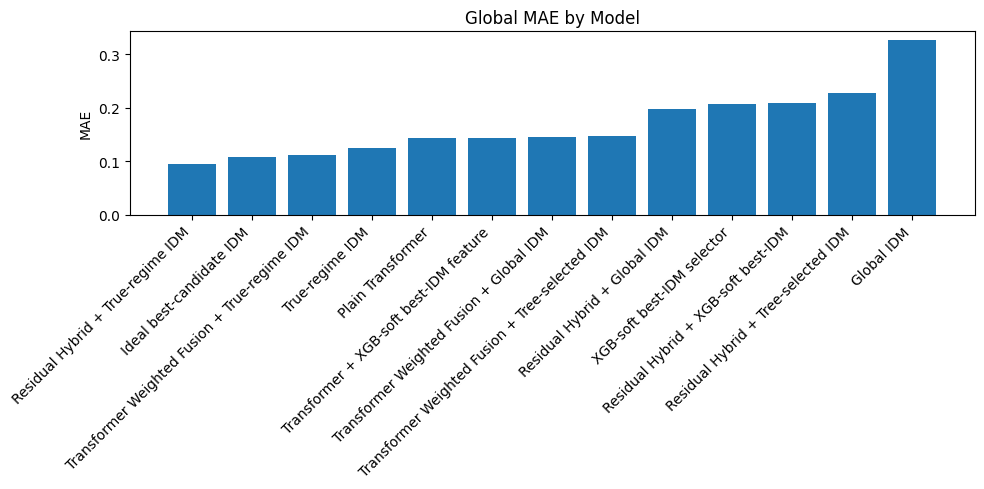

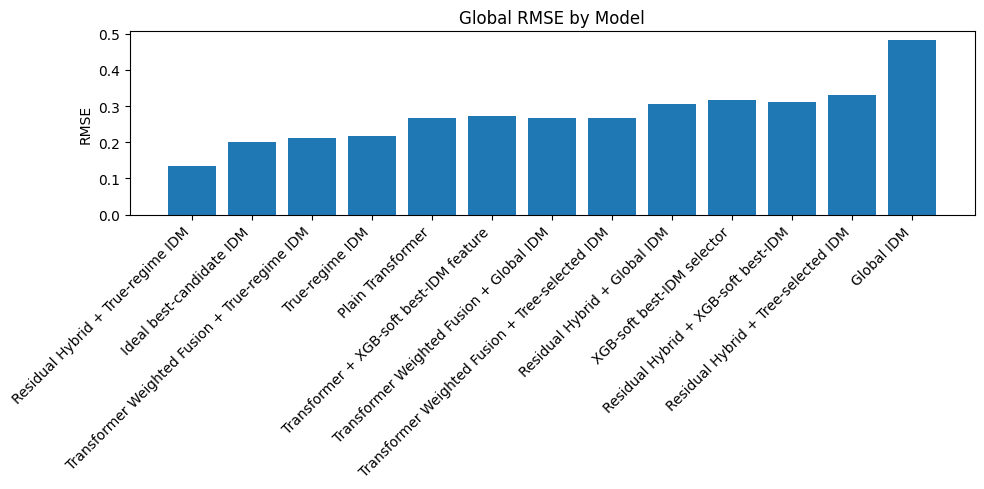

In [108]:
# ============================================================
# PLOT: GLOBAL MAE AND RMSE
# ============================================================

plot_df = global_metrics_df.sort_values("MAE")

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(plot_df))
ax.bar(x, plot_df["MAE"])
ax.set_title("Global MAE by Model")
ax.set_ylabel("MAE")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"], rotation=45, ha="right")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "plot_global_mae.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(plot_df))
ax.bar(x, plot_df["RMSE"])
ax.set_title("Global RMSE by Model")
ax.set_ylabel("RMSE")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"], rotation=45, ha="right")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "plot_global_rmse.png", dpi=300)
plt.show()

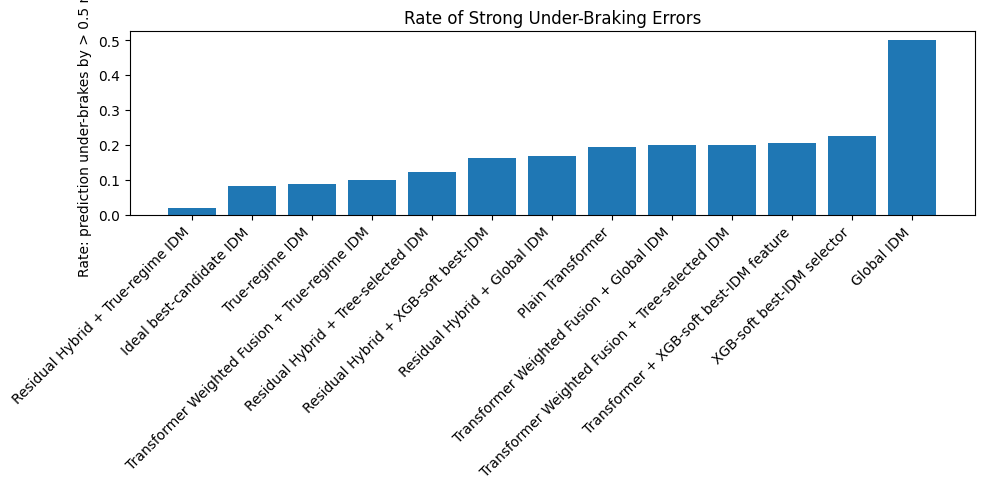

In [109]:
# ============================================================
# PLOT: BRAKING UNDERPREDICTION RATE
# ============================================================

plot_df = braking_safety_df.sort_values("UnderBrake_Rate_gt_0p5")

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(plot_df))
ax.bar(x, plot_df["UnderBrake_Rate_gt_0p5"])
ax.set_title("Rate of Strong Under-Braking Errors")
ax.set_ylabel("Rate: prediction under-brakes by > 0.5 m/s²")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"], rotation=45, ha="right")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "plot_underbraking_rate.png", dpi=300)
plt.show()

In [110]:
# ============================================================
# REGIME MAE TABLE FOR EXPORT
# ============================================================

regime_mae_pivot = regime_metrics_df.pivot(
    index="Model",
    columns="Regime",
    values="MAE"
).reset_index()

print("=== REGIME MAE PIVOT ===")
print(regime_mae_pivot.to_string(index=False))

=== REGIME MAE PIVOT ===
                                          Model  accelerating  braking   steady
                                     Global IDM      0.351277 0.567379 0.228490
                       Ideal best-candidate IDM      0.143548 0.176254 0.062797
                              Plain Transformer      0.189335 0.329021 0.052537
                   Residual Hybrid + Global IDM      0.326741 0.337882 0.077763
            Residual Hybrid + Tree-selected IDM      0.424031 0.283484 0.100077
              Residual Hybrid + True-regime IDM      0.102045 0.116373 0.084802
            Residual Hybrid + XGB-soft best-IDM      0.354946 0.335935 0.086348
        Transformer + XGB-soft best-IDM feature      0.183687 0.345706 0.050873
       Transformer Weighted Fusion + Global IDM      0.197913 0.331890 0.050234
Transformer Weighted Fusion + Tree-selected IDM      0.193152 0.338228 0.053018
  Transformer Weighted Fusion + True-regime IDM      0.138342 0.211149 0.059913
               

In [ ]:
# ============================================================
# SAVE OUTPUTS
# ============================================================

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_tag = f"{SEQUENCE_TAG}_{THRESHOLD_TAG}_{IDM_PARAM_TAG}"

global_metrics_df.to_csv(
    OUTPUT_DIR / f"secondary_global_metrics_{output_tag}.csv",
    index=False
)

regime_metrics_df.to_csv(
    OUTPUT_DIR / f"secondary_regime_metrics_{output_tag}.csv",
    index=False
)

tail_metrics_df.to_csv(
    OUTPUT_DIR / f"secondary_tail_metrics_{output_tag}.csv",
    index=False
)

braking_safety_df.to_csv(
    OUTPUT_DIR / f"secondary_braking_safety_metrics_{output_tag}.csv",
    index=False
)

severe_braking_df.to_csv(
    OUTPUT_DIR / f"secondary_severe_braking_metrics_{output_tag}.csv",
    index=False
)

sign_metrics_df.to_csv(
    OUTPUT_DIR / f"secondary_sign_consistency_metrics_{output_tag}.csv",
    index=False
)

critical_metrics_df.to_csv(
    OUTPUT_DIR / f"secondary_critical_situation_metrics_{output_tag}.csv",
    index=False
)

safety_summary_df.to_csv(
    OUTPUT_DIR / f"secondary_final_safety_summary_{output_tag}.csv",
    index=False
)

regime_mae_pivot.to_csv(
    OUTPUT_DIR / f"secondary_regime_mae_pivot_{output_tag}.csv",
    index=False
)

with open(OUTPUT_DIR / f"secondary_config_{output_tag}.json", "w") as f:
    json.dump({
        "SEQUENCE_TAG": SEQUENCE_TAG,
        "THRESHOLD_TAG": THRESHOLD_TAG,
        "IDM_PARAM_TAG": IDM_PARAM_TAG,
        "BRAKE_THRESHOLD": BRAKE_THRESHOLD,
        "ACCEL_THRESHOLD": ACCEL_THRESHOLD,
        "STRONG_BRAKE_THRESHOLD": STRONG_BRAKE_THRESHOLD,
        "SEVERE_BRAKE_THRESHOLD": SEVERE_BRAKE_THRESHOLD,
        "LARGE_ERROR_THRESHOLD": LARGE_ERROR_THRESHOLD,
        "FPS": FPS,
        "HISTORY": HISTORY,
        "HORIZON": HORIZON,
        "HORIZON_SECONDS": HORIZON_SECONDS,
        "STRIDE": STRIDE,
        "models_loaded": list(std_model_dfs.keys())
    }, f, indent=2)

print("Saved secondary evaluation outputs to:")
print(OUTPUT_DIR)
print("Output tag:", output_tag)

Saved secondary evaluation outputs to:
C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\secondary_safety_evaluation
Output tag: H25_Hz1_S1_brake0p1_accel0p2_refinedIDM_v2


: 